In [14]:
import pandas as pd
purchases = pd.read_csv("新新出入境数据（英文版）.csv")
print("rows, columns:", purchases.shape)
print(purchases.head())

rows, columns: (23428, 7)
         Date                   Control Point Arrival / Departure  Hong Kong Residents  Mainland Visitors  Other Visitors  Total
0  13-11-2023                         Airport             Arrival                29286               7737           18942  55965
1  13-11-2023                         Airport           Departure                24590               5925           17591  48106
2  13-11-2023  Express Rail Link West Kowloon             Arrival                14226              12544             984  27754
3  13-11-2023  Express Rail Link West Kowloon           Departure                11981              10275            1063  23319
4  13-11-2023                           Lo Wu             Arrival                61184              11195             700  73079


In [15]:
import pandas as pd

# 增加这两行显示设置，防止控制台输出折行错位
pd.set_option('display.max_columns', None)  # 显示所有列
pd.set_option('display.width', 1000)        # 设置显示总宽度，数字可调大

df = pd.read_csv("新新出入境数据（英文版）.csv")
numeric_cols = ['Hong Kong Residents', 'Mainland Visitors', 'Other Visitors', 'Total']

grouped_stats = df.groupby('Control Point')[numeric_cols].agg(
    ['max', 'min', 'mean', 'median', 'var']
)

print(grouped_stats.round(2))

                               Hong Kong Residents                                        Mainland Visitors                                      Other Visitors                                       Total                                       
                                               max   min      mean   median           var               max  min      mean   median          var            max min      mean   median          var     max   min      mean   median           var
Control Point                                                                                                                                                                                                                                     
Airport                                      77540    24  31596.54  29729.5  7.465752e+07             48740    2  10394.98   9429.5  17308185.00          36173  14  18331.32  17841.5  17405002.28   93386    88  60322.83  59536.0  8.984565e+07
China Ferry Terminal        

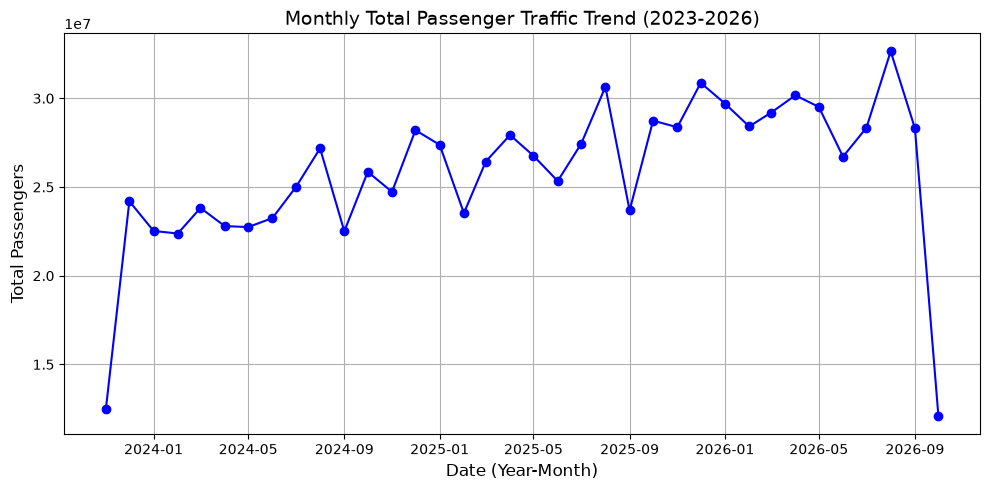

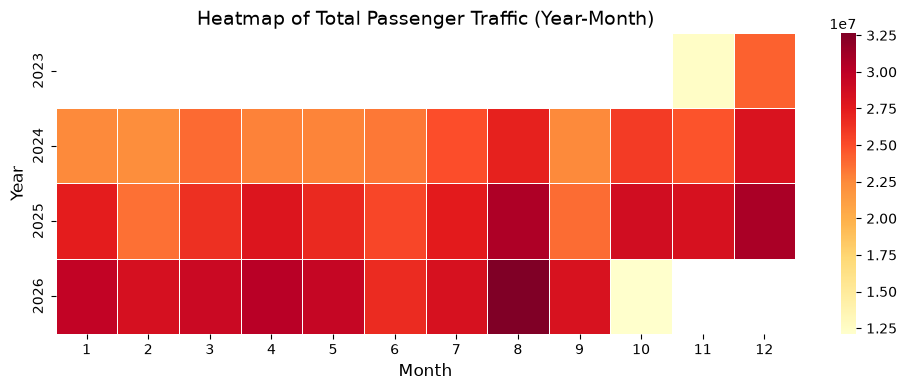

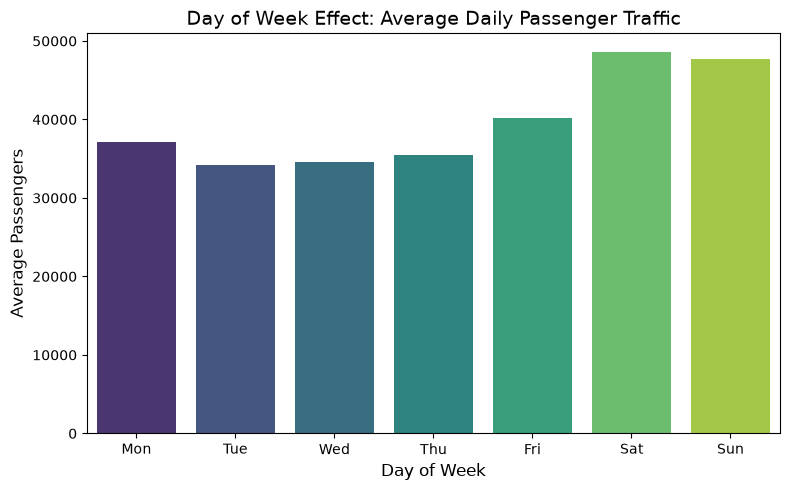

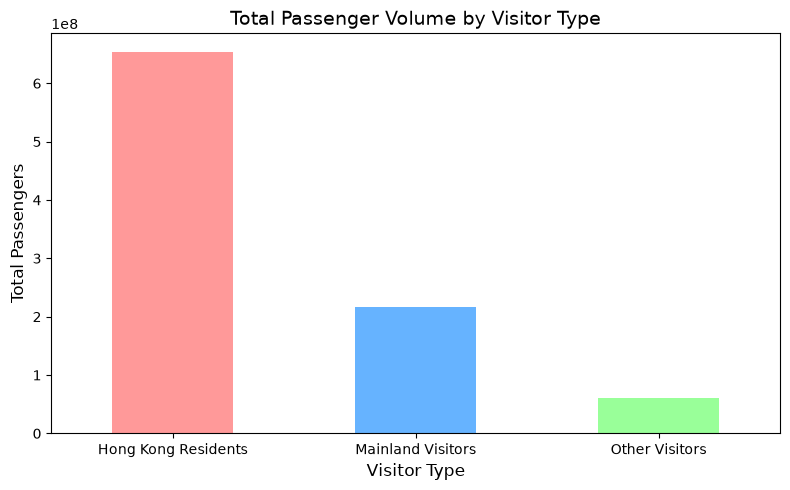

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# 1. 屏蔽字体警告，强制重置为默认英文字体（彻底解决报错问题）
warnings.filterwarnings('ignore', category=UserWarning, module='matplotlib.font_manager')
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']

# 2. 读取数据并处理日期格式
df = pd.read_csv("新新出入境数据（英文版）.csv")
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')

# ==========================================
# Plot 1: Line Chart - Monthly Total Trend
# ==========================================
# 按月聚合数据
monthly_trend = df.groupby(df['Date'].dt.to_period('M'))['Total'].sum().reset_index()
monthly_trend['Date'] = monthly_trend['Date'].dt.to_timestamp()

plt.figure(figsize=(10, 5))
plt.plot(monthly_trend['Date'], monthly_trend['Total'], marker='o', linestyle='-', color='b')
plt.title('Monthly Total Passenger Traffic Trend (2023-2026)', fontsize=14)
plt.xlabel('Date (Year-Month)', fontsize=12)
plt.ylabel('Total Passengers', fontsize=12)
plt.grid(True)
plt.tight_layout()
plt.show()

# ==========================================
# Plot 2: Heatmap - Year/Month Traffic
# ==========================================
# 提取年份和月份
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
# 构建数据透视表
heatmap_data = df.groupby(['Year', 'Month'])['Total'].sum().unstack()

plt.figure(figsize=(10, 4))
sns.heatmap(heatmap_data, annot=False, cmap='YlOrRd', fmt='g', linewidths=.5)
plt.title('Heatmap of Total Passenger Traffic (Year-Month)', fontsize=14)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Year', fontsize=12)
plt.tight_layout()
plt.show()

# ==========================================
# Plot 3: Bar Chart - Day of Week Effect
# ==========================================
# 提取星期并将标签改为英文简写
df['DayOfWeek'] = df['Date'].dt.dayofweek 
days_map = {0: 'Mon', 1: 'Tue', 2: 'Wed', 3: 'Thu', 4: 'Fri', 5: 'Sat', 6: 'Sun'}

# 计算每周各天的平均单日人流量
df_dow = df.groupby('DayOfWeek')['Total'].mean().reset_index()
df_dow['DayName'] = df_dow['DayOfWeek'].map(days_map)

plt.figure(figsize=(8, 5))
sns.barplot(x='DayName', y='Total', data=df_dow, hue='DayName', palette='viridis', legend=False)
plt.title('Day of Week Effect: Average Daily Passenger Traffic', fontsize=14)
plt.xlabel('Day of Week', fontsize=12)
plt.ylabel('Average Passengers', fontsize=12)
plt.tight_layout()
plt.show()

# ==========================================
# Plot 4: Bar Chart - Passenger Composition
# ==========================================
visitor_types = ['Hong Kong Residents', 'Mainland Visitors', 'Other Visitors']
type_sums = df[visitor_types].sum()

plt.figure(figsize=(8, 5))
type_sums.plot(kind='bar', color=['#ff9999','#66b3ff','#99ff99'])
plt.title('Total Passenger Volume by Visitor Type', fontsize=14)
plt.xlabel('Visitor Type', fontsize=12)
plt.ylabel('Total Passengers', fontsize=12)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

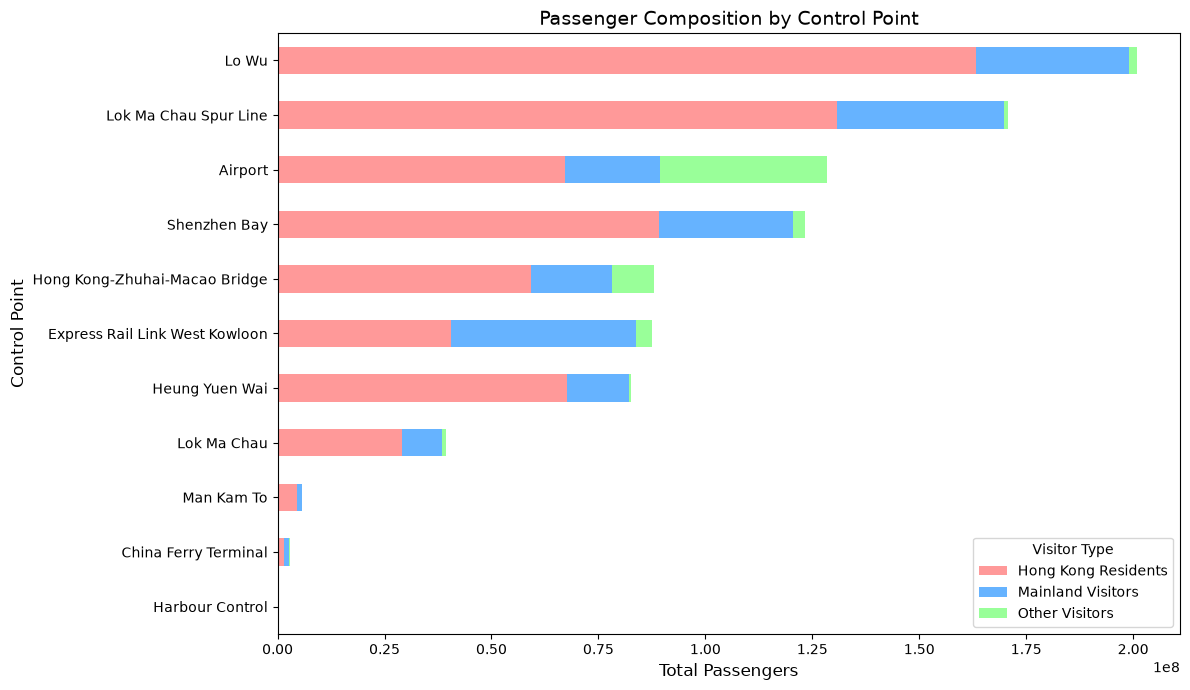

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import warnings

# 1. 屏蔽掉底层所有关于字体的烦人警告（直接清净）
warnings.filterwarnings('ignore', category=UserWarning, module='matplotlib.font_manager')

# 2. 强制重置 Matplotlib 的全局设置到初始默认状态
plt.rcParams.update(plt.rcParamsDefault)

# 3. 显式指定绝对安全的英文字体
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']

# 读取数据
df = pd.read_csv("新新出入境数据（英文版）.csv")

# 提取三种旅客类型的列
visitor_types = ['Hong Kong Residents', 'Mainland Visitors', 'Other Visitors']

# 按口岸分组，并计算三种旅客的总量
cp_types = df.groupby('Control Point')[visitor_types].sum()

# 计算每个口岸的总客流量并排序
cp_types['Total_Sort'] = cp_types.sum(axis=1)
cp_types = cp_types.sort_values(by='Total_Sort', ascending=True).drop(columns='Total_Sort')

# 绘制横向堆叠柱状图
plt.figure(figsize=(12, 7))
cp_types.plot(
    kind='barh', 
    stacked=True, 
    color=['#ff9999', '#66b3ff', '#99ff99'], 
    ax=plt.gca()
)

# 纯英文标签
plt.title('Passenger Composition by Control Point', fontsize=14)
plt.xlabel('Total Passengers', fontsize=12)
plt.ylabel('Control Point', fontsize=12)
plt.legend(title='Visitor Type', loc='lower right')
plt.tight_layout()

# 显示图表
plt.show()

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
purchases = pd.read_csv("新新出入境数据（英文版）.csv")
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y', errors='coerce')
target_direction = "Arrival"
df_dir = df[df['Arrival / Departure'] == target_direction].copy()
control_points = df_dir['Control Point'].unique()
print(f"共发现 {len(control_points)} 个口岸，开始按口岸使用 Statsmodels 进行回归...\n")

# 自定义评估指标函数（替代 sklearn 的 metrics）
def calc_rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def calc_mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

results = {}

# 5. 按 Control Point 循环遍历并建模
for cp in control_points:
    print(f"======================================")
    print(f"正在处理口岸: {cp}")

# 筛选当前口岸数据
    df_cp = df_dir[df_dir['Control Point'] == cp].sort_values('Date').copy()
    df_cp.set_index('Date', inplace=True)

# 重建完整时间轴并插值补齐
    full_idx = pd.date_range(start=df_cp.index.min(), end=df_cp.index.max(), freq='D')
    df_ts = df_cp.reindex(full_idx)
    df_ts['Total'] = df_ts['Total'].interpolate(method='linear')

# 6. 特征工程
    model_df = pd.DataFrame(index=df_ts.index)
    model_df['y'] = df_ts['Total']
    
    model_df['lag_1'] = model_df['y'].shift(1)
    model_df['lag_7'] = model_df['y'].shift(7)
    model_df['rolling_mean_7'] = model_df['y'].shift(1).rolling(window=7).mean()
    model_df['day_of_week'] = model_df.index.dayofweek
    model_df['is_weekend'] = model_df.index.dayofweek.isin([5, 6]).astype(int)
    
    model_df = model_df.dropna()
    
    if len(model_df) < 30:
        print(f"数据量太少 ({len(model_df)} 行)，跳过建模。")
        continue

# 7. 划分训练集与测试集（前 80% 训练，后 20% 测试）
    train_size = int(len(model_df) * 0.8)
    train_data = model_df.iloc[:train_size]
    test_data = model_df.iloc[train_size:]

X_train, y_train = train_data.drop(columns=['y']), train_data['y']
X_test, y_test = test_data.drop(columns=['y']), test_data['y']
X_train_sm = sm.add_constant(X_train)
X_test_sm = sm.add_constant(X_test)
model = sm.OLS(y_train, X_train_sm).fit()

# 9. 预测与评估
y_pred = model.predict(X_test_sm)
rmse = calc_rmse(y_test, y_pred)
mape = calc_mape(y_test, y_pred)

print(f"测试集 RMSE: {rmse:.2f}")
print(f"测试集 MAPE: {mape:.2f}%")

print(f"测试集 RMSE: {rmse:.2f}")
print(f"测试集 MAPE: {mape:.2f}%")

print("\n所有口岸回归建模完成！")

共发现 11 个口岸，开始按口岸使用 Statsmodels 进行回归...

正在处理口岸: Airport
正在处理口岸: Express Rail Link West Kowloon
正在处理口岸: Lo Wu
正在处理口岸: Lok Ma Chau Spur Line
正在处理口岸: Heung Yuen Wai
正在处理口岸: Hong Kong-Zhuhai-Macao Bridge
正在处理口岸: Lok Ma Chau
正在处理口岸: Man Kam To
正在处理口岸: Shenzhen Bay
正在处理口岸: China Ferry Terminal
正在处理口岸: Harbour Control
测试集 RMSE: 37.15
测试集 MAPE: 59.37%
测试集 RMSE: 37.15
测试集 MAPE: 59.37%

所有口岸回归建模完成！


In [21]:
import warnings
import pandas as pd
import numpy as np
from statsmodels.tsa.stattools import adfuller

# 忽略 statsmodels 的未来版本提示警告
warnings.simplefilter(action='ignore', category=FutureWarning)

# 3. 选择进出境方向（以 "Arrival" 抵港为例）
target_direction = "Arrival"
df_dir = df[df['Arrival / Departure'] == target_direction].copy()

control_points = df_dir['Control Point'].unique()
print(f"共发现 {len(control_points)} 个口岸，开始进行平稳性检验及差分处理...\n")
print(f"{'Control Point':<32} | {'原始p值':<8} | {'原始是否平稳':<12} | {'差分后p值':<10} | {'差分后是否平稳'}")
print("-" * 85)

for cp in control_points:
    df_cp = df_dir[df_dir['Control Point'] == cp].sort_values('Date').copy()
    df_cp = df_cp.set_index('Date')
    
    full_idx = pd.date_range(start=df_cp.index.min(), end=df_cp.index.max(), freq='D')
    df_ts = df_cp.reindex(full_idx)
    series = df_ts['Total'].interpolate(method='linear').dropna()
    
    # 原始序列 ADF 检验
    res_orig = adfuller(series, result_object=False)
    p_orig = res_orig[1]
    is_stat_orig = p_orig < 0.05
    
    # 如果原始序列不平稳，进行一阶差分再检验
    if not is_stat_orig:
        series_diff = series.diff().dropna()
        res_diff = adfuller(series_diff, result_object=False)
        p_diff = res_diff[1]
        is_stat_diff = p_diff < 0.05
        diff_str = f"{p_diff:.4f} ({str(is_stat_diff)})"
    else:
        diff_str = "无需差分 (N/A)"
    
    print(f"{cp:<32} | {p_orig:>8.4f} | {str(is_stat_orig):<12} | {diff_str}")

print("-" * 85)
print("平稳性检验与差分验证全部完成！")

共发现 11 个口岸，开始进行平稳性检验及差分处理...

Control Point                    | 原始p值     | 原始是否平稳       | 差分后p值      | 差分后是否平稳
-------------------------------------------------------------------------------------
Airport                          |   0.0000 | True         | 无需差分 (N/A)
Express Rail Link West Kowloon   |   0.0001 | True         | 无需差分 (N/A)
Lo Wu                            |   0.0270 | True         | 无需差分 (N/A)
Lok Ma Chau Spur Line            |   0.0205 | True         | 无需差分 (N/A)
Heung Yuen Wai                   |   0.1141 | False        | 0.0000 (True)
Hong Kong-Zhuhai-Macao Bridge    |   0.0000 | True         | 无需差分 (N/A)
Lok Ma Chau                      |   0.0045 | True         | 无需差分 (N/A)
Man Kam To                       |   0.6118 | False        | 0.0000 (True)
Shenzhen Bay                     |   0.2068 | False        | 0.0000 (True)
China Ferry Terminal             |   0.0006 | True         | 无需差分 (N/A)
Harbour Control                  |   0.0000 | True         | 无需差分 (N/A)
-

In [22]:
import warnings
import pandas as pd
import numpy as np
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA

# 忽略警告信息
warnings.simplefilter('ignore')

# 3. 选择进出境方向（以 "Arrival" 抵港为例）
target_direction = "Arrival"
df_dir = df[df['Arrival / Departure'] == target_direction].copy()

control_points = df_dir['Control Point'].unique()
print(f"共发现 {len(control_points)} 个口岸，开始按口岸批量构建 ARIMA 模型...\n")
print(f"{'Control Point':<32} | {'自动判定 d':<10} | {'Test RMSE':<12} | {'Test MAPE'}")
print("-" * 75)

arima_results = {}

# 4. 核心：遍历每个口岸分别训练 ARIMA
for cp in control_points:
    df_cp = df_dir[df_dir['Control Point'] == cp].sort_values('Date').copy()
    df_cp = df_cp.set_index('Date')
    
    full_idx = pd.date_range(start=df_cp.index.min(), end=df_cp.index.max(), freq='D')
    df_ts = df_cp.reindex(full_idx)
    series = df_ts['Total'].interpolate(method='linear').dropna()
    
    # 5. 根据 ADF 检验结果自动确定阶数 d
    res_adf = adfuller(series)
    d = 0 if res_adf[1] < 0.05 else 1  # p < 0.05 为平稳 (d=0)，否则差分 (d=1)
    
    # 6. 划分训练集与测试集 (前 80% 训练，后 20% 测试)
    train_size = int(len(series) * 0.8)
    train, test = series.iloc[:train_size], series.iloc[train_size:]
    
    try:
        # 7. 训练 ARIMA 模型 (这里以基础的 p=1, d=d, q=1 为例)
        model = ARIMA(train, order=(1, d, 1))
        model_fit = model.fit()
        
        # 8. 对测试集长度进行向后预测
        forecast = model_fit.forecast(steps=len(test))
        
        # 9. 计算评估指标 (RMSE 与防分母过小的 MAPE)
        rmse = np.sqrt(np.mean((test - forecast) ** 2))
        mask = test > 10
        mape = np.mean(np.abs((test[mask] - forecast[mask]) / test[mask])) * 100 if mask.sum() > 0 else 0.0
        
        arima_results[cp] = {
            "model_fit": model_fit,
            "forecast": forecast,
            "test_actual": test,
            "rmse": rmse,
            "mape": mape
        }
        
        print(f"{cp:<32} | d = {d:<7} | {rmse:>12.2f} | {mape:>6.2f}%")
        
    except Exception as e:
        print(f"{cp:<32} | 建模失败: {e}")

print("-" * 75)
print("所有口岸 ARIMA 模型训练与预测完成！")

共发现 11 个口岸，开始按口岸批量构建 ARIMA 模型...

Control Point                    | 自动判定 d     | Test RMSE    | Test MAPE
---------------------------------------------------------------------------
Airport                          | d = 0       |      9235.08 |  11.63%
Express Rail Link West Kowloon   | d = 0       |     14342.52 |  20.36%


Lo Wu                            | d = 0       |     21914.94 |  12.83%
Lok Ma Chau Spur Line            | d = 0       |     19244.52 |  13.05%
Heung Yuen Wai                   | d = 1       |      8366.53 |  13.67%
Hong Kong-Zhuhai-Macao Bridge    | d = 0       |     15541.81 |  22.20%
Lok Ma Chau                      | d = 0       |      6758.71 |  18.39%
Man Kam To                       | d = 1       |       626.81 |  13.85%
Shenzhen Bay                     | d = 1       |     19636.36 |  18.89%
China Ferry Terminal             | d = 0       |       756.44 |  89.76%
Harbour Control                  | d = 0       |        37.28 |  54.49%
---------------------------------------------------------------------------
所有口岸 ARIMA 模型训练与预测完成！


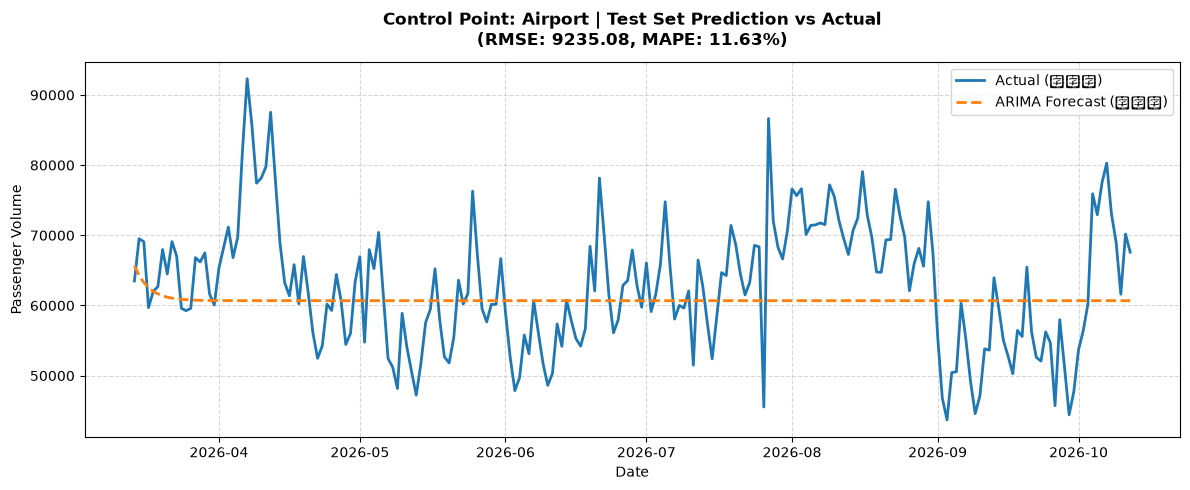

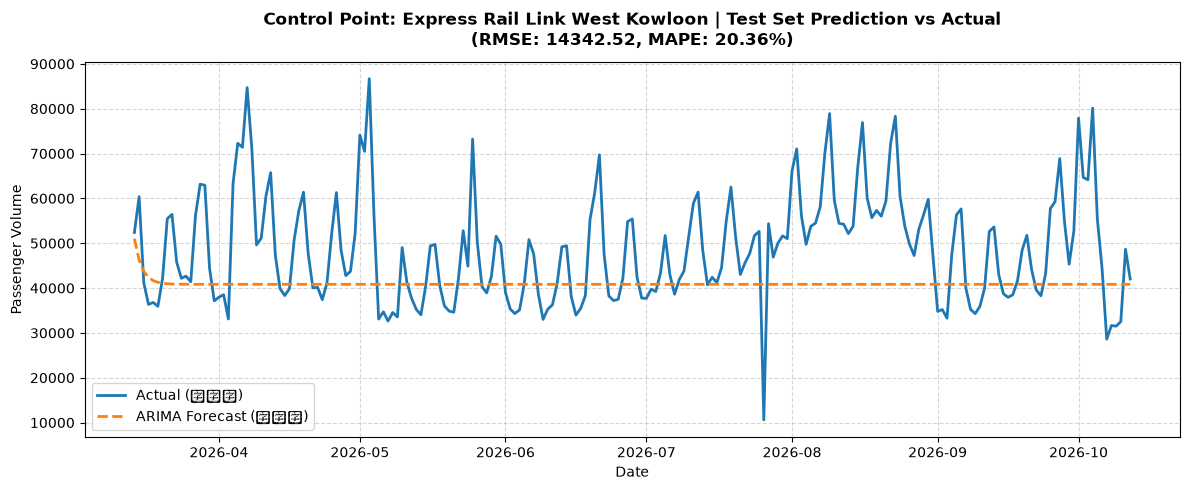

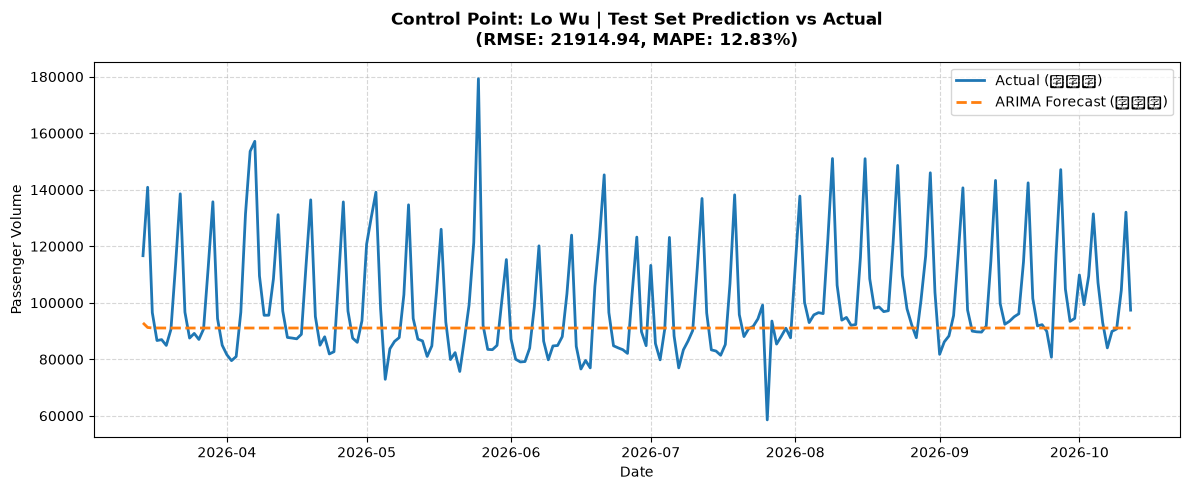

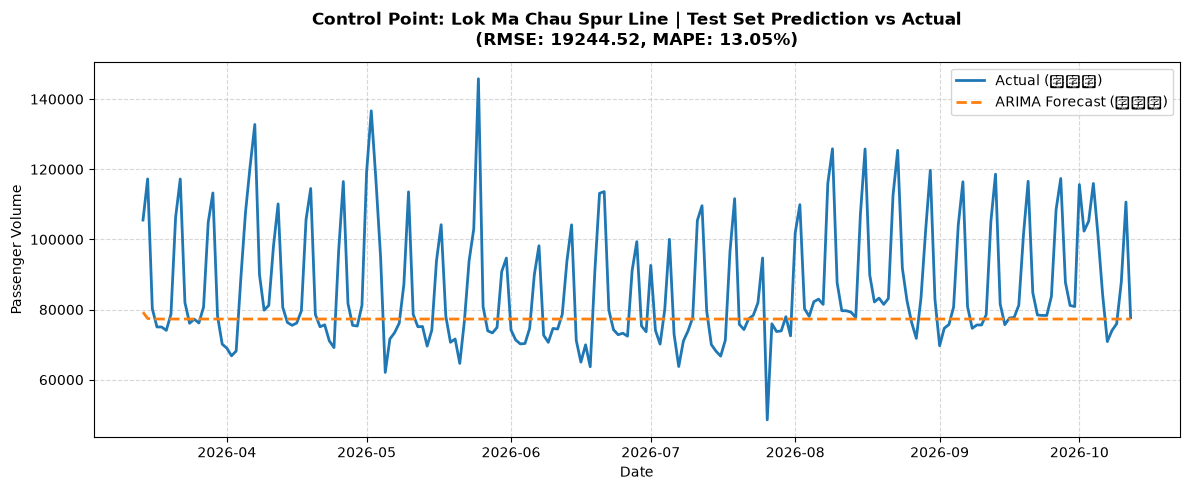

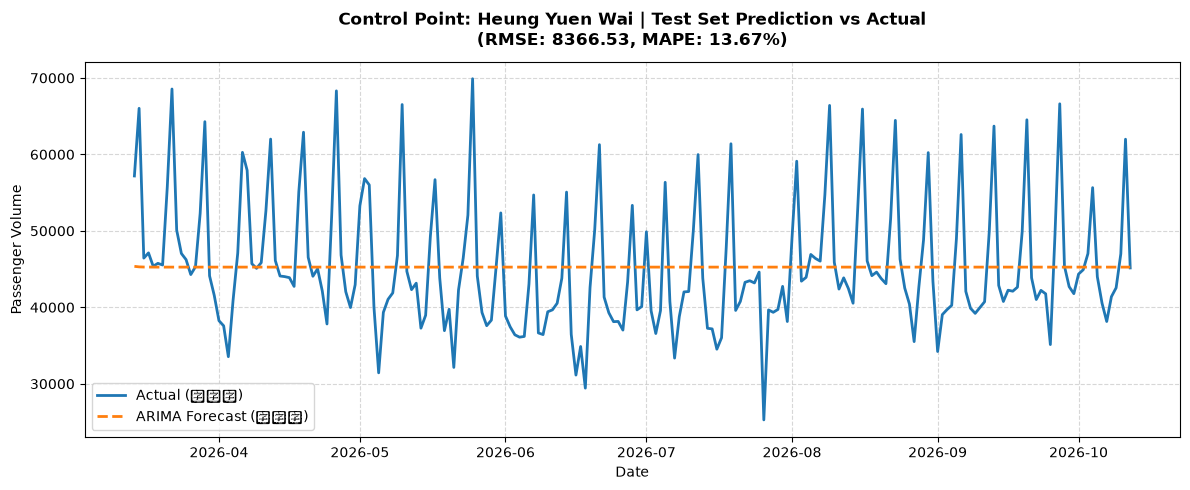

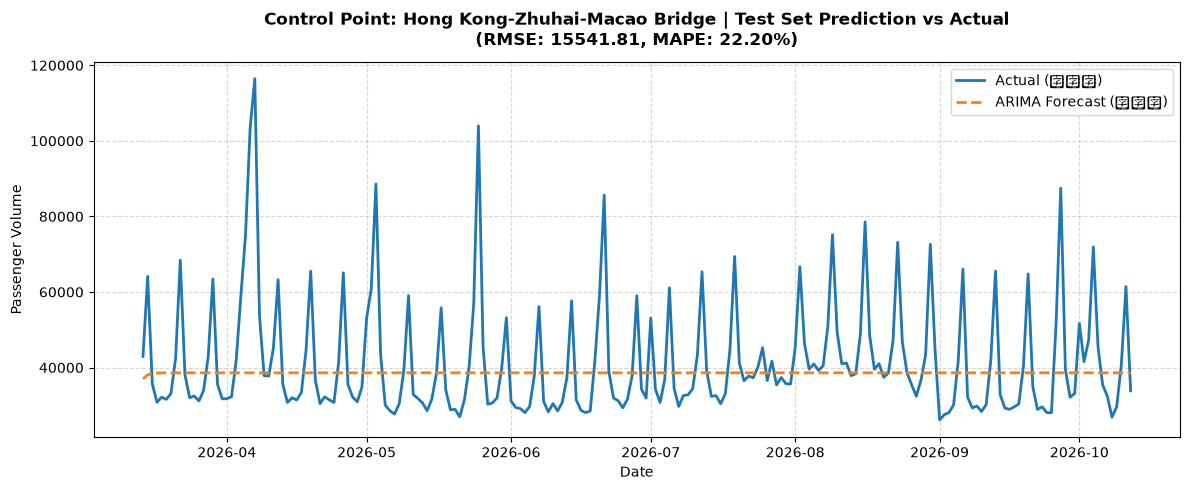

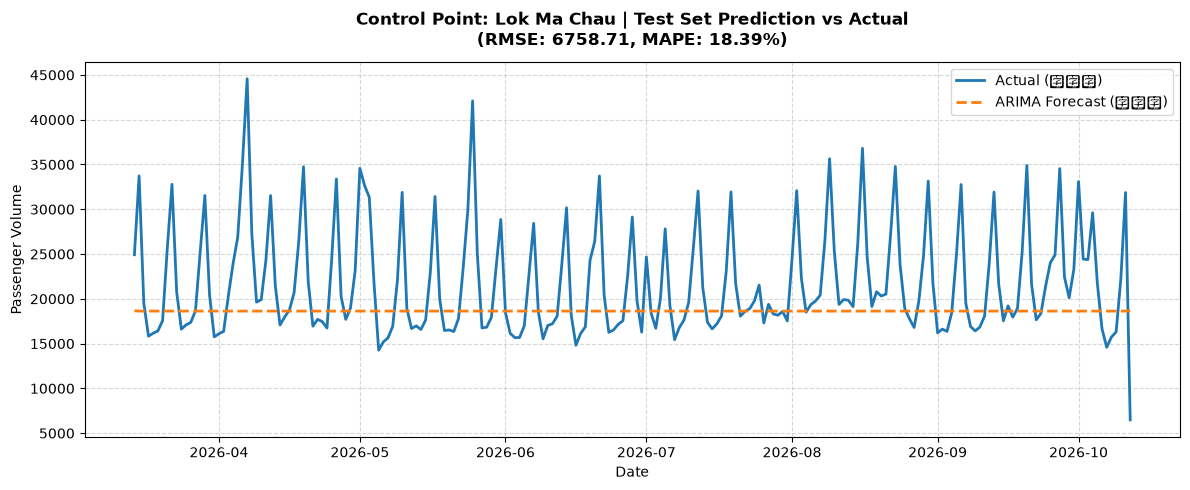

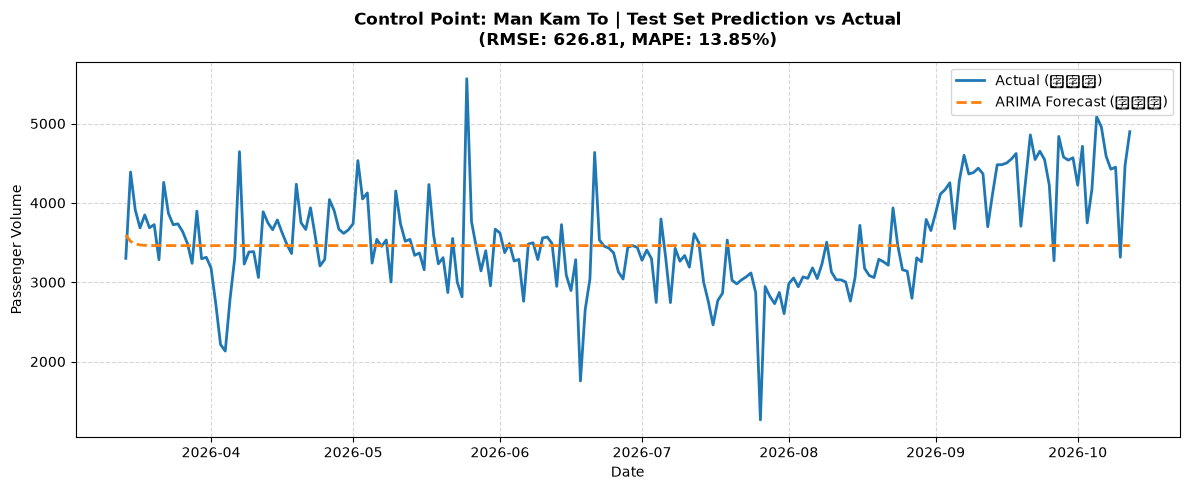

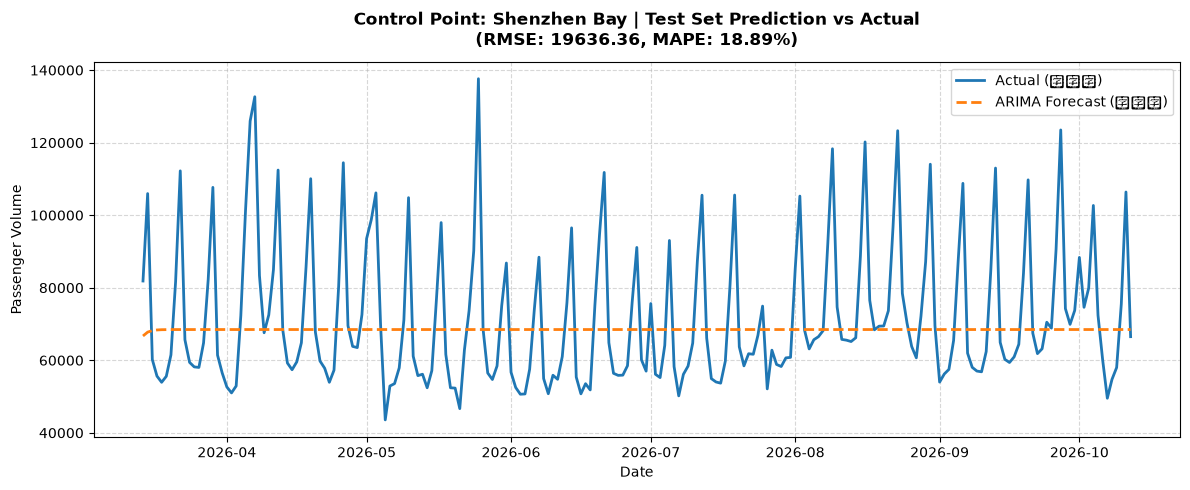

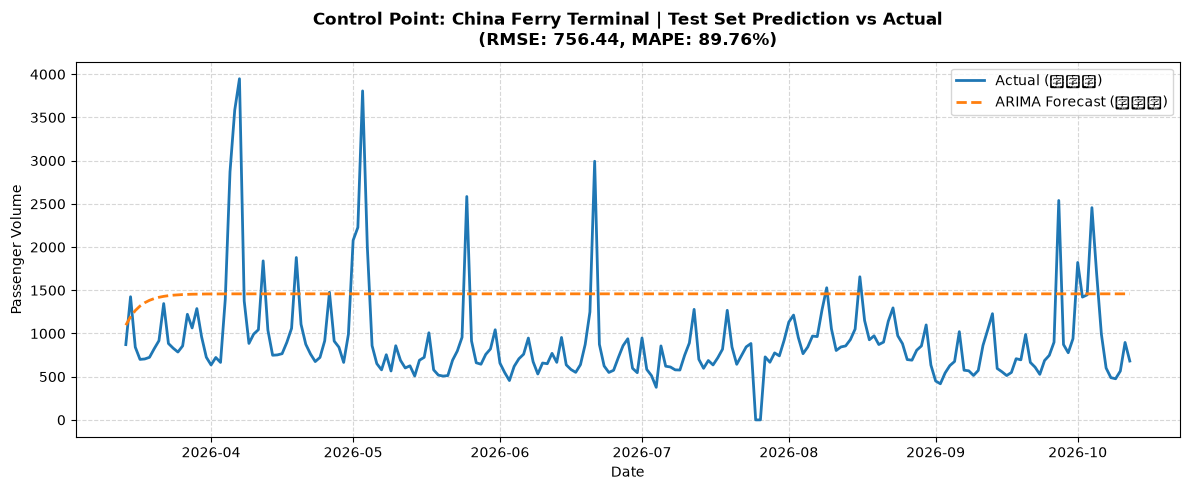

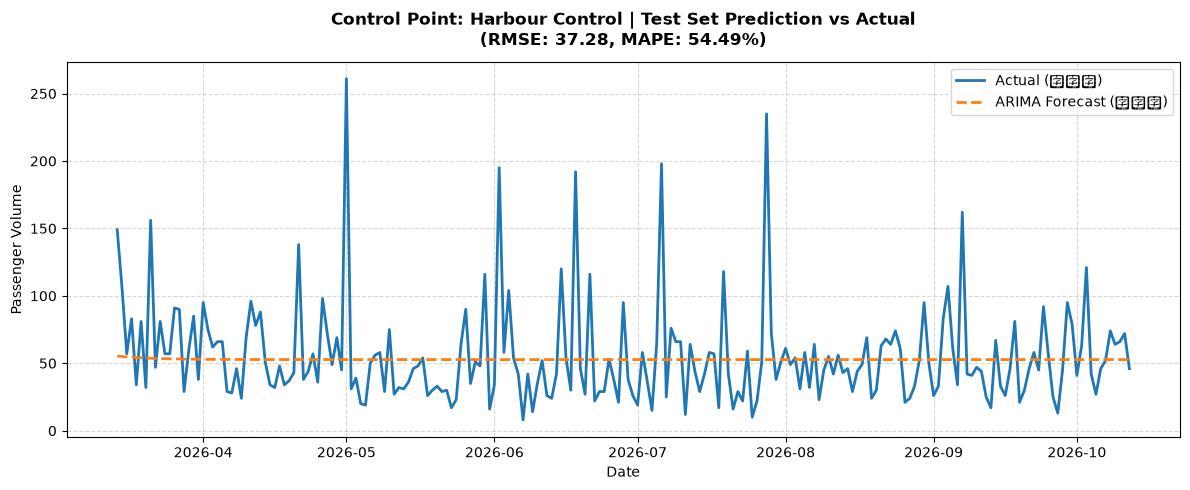

In [29]:
import matplotlib.pyplot as plt

# 解决图表中文乱码和负号显示问题
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

# 遍历所有成功训练的口岸，绘制测试集预测对比图
for cp, res in arima_results.items():
    test_actual = res["test_actual"]
    forecast = res["forecast"]
    rmse = res["rmse"]
    mape = res["mape"]
    
    plt.figure(figsize=(12, 5))
    
    # 绘制真实值
    plt.plot(test_actual.index, test_actual.values, label='Actual (真实值)', color='#1f77b4', linewidth=2)
    
    # 绘制 ARIMA 预测值
    plt.plot(test_actual.index, forecast.values, label='ARIMA Forecast (预测值)', color='#ff7f0e', linestyle='--', linewidth=2)
    
    # 图表装饰
    plt.title(f"Control Point: {cp} | Test Set Prediction vs Actual\n(RMSE: {rmse:.2f}, MAPE: {mape:.2f}%)", 
              fontsize=12, fontweight='bold', pad=12)
    plt.xlabel('Date', fontsize=10)
    plt.ylabel('Passenger Volume', fontsize=10)
    plt.legend(loc='best', frameon=True)
    plt.grid(True, linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()

In [23]:
import warnings
import pandas as pd
import numpy as np
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.simplefilter('ignore')

# 1. 数据预处理
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y', errors='coerce')
df_dir = df[df['Arrival / Departure'] == 'Arrival'].copy()

print(f"{'Control Point':<32} | {'残差均值':<10} | {'Ljung-Box p值':<15} | {'残差是否为白噪声 (p>0.05)'}")
print("-" * 80)

for cp in df_dir['Control Point'].unique():
    df_cp = df_dir[df_dir['Control Point'] == cp].sort_values('Date').copy()
    df_cp = df_cp.set_index('Date')
    
    full_idx = pd.date_range(start=df_cp.index.min(), end=df_cp.index.max(), freq='D')
    df_ts = df_cp.reindex(full_idx)
    series = df_ts['Total'].interpolate(method='linear').dropna()
    
    # 确定 d 值
    res_adf = adfuller(series)
    d = 0 if res_adf[1] < 0.05 else 1
    
    # 训练集建模
    train_size = int(len(series) * 0.8)
    train = series.iloc[:train_size]
    
    try:
        model = ARIMA(train, order=(1, d, 1))
        model_fit = model.fit()
        
        # 获取训练集残差
        residuals = model_fit.resid
        
        # 1. 残差均值
        resid_mean = np.mean(residuals)
        
        # 2. Ljung-Box 白噪声检验 (检验滞后 10 期是否存在自相关)
        lb_test = acorr_ljungbox(residuals, lags=[10], return_df=True)
        lb_pvalue = lb_test['lb_pvalue'].iloc[0]
        
        # p > 0.05 说明残差无自相关，是合格的白噪声
        is_white_noise = lb_pvalue > 0.05
        
        print(f"{cp:<32} | {resid_mean:>10.2f} | {lb_pvalue:>15.4f} | {str(is_white_noise):<10}")
        
    except Exception as e:
        print(f"{cp:<32} | 诊断失败: {e}")

print("-" * 80)
print("残差诊断检验完成！")

Control Point                    | 残差均值       | Ljung-Box p值    | 残差是否为白噪声 (p>0.05)
--------------------------------------------------------------------------------
Airport                          |       5.22 |          0.0000 | False     
Express Rail Link West Kowloon   |       5.46 |          0.0000 | False     
Lo Wu                            |      -0.34 |          0.0000 | False     
Lok Ma Chau Spur Line            |      -0.79 |          0.0000 | False     
Heung Yuen Wai                   |     607.17 |          0.0000 | False     
Hong Kong-Zhuhai-Macao Bridge    |      -2.19 |          0.0000 | False     
Lok Ma Chau                      |      -0.64 |          0.0000 | False     
Man Kam To                       |      18.26 |          0.0000 | False     
Shenzhen Bay                     |    1351.25 |          0.0000 | False     
China Ferry Terminal             |      -0.40 |          0.0000 | False     
Harbour Control                  |       0.00 |          0.4889 |

Generated updated theoretical analysis for Control Point model.


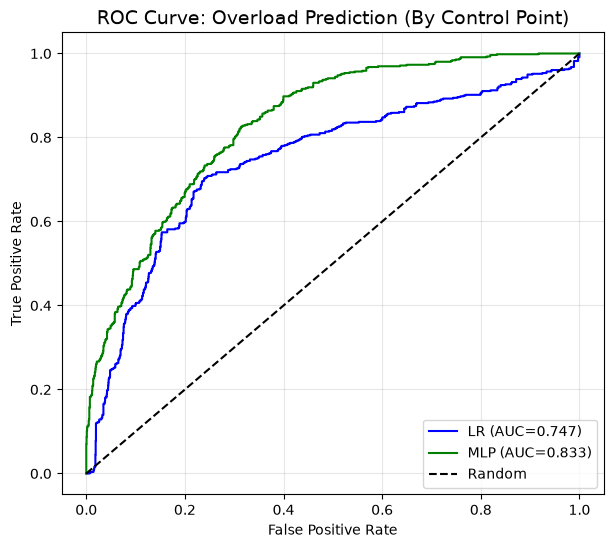

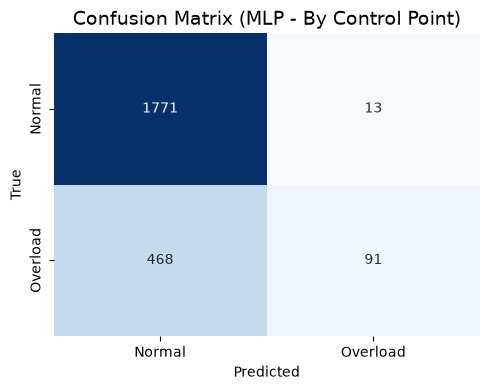

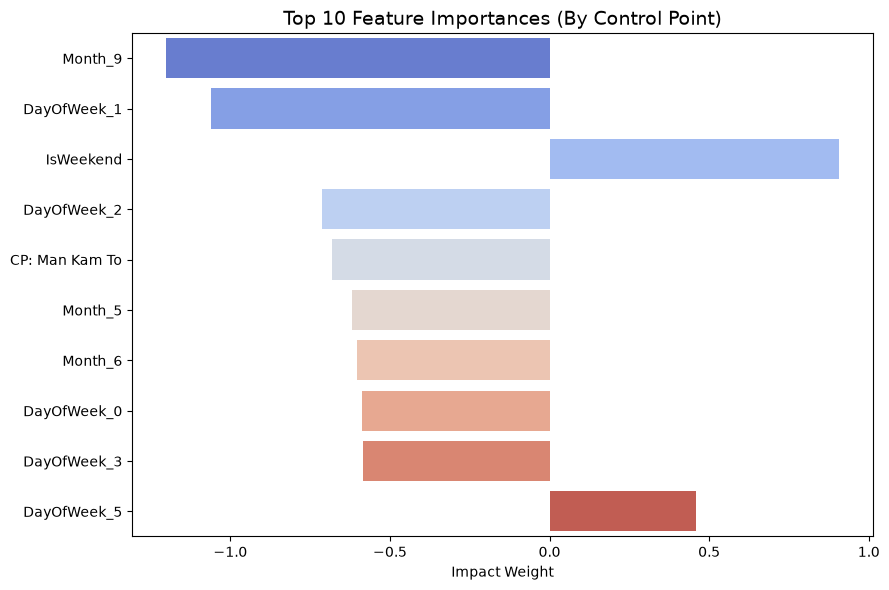

Generated.


In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']

# 1. Data Prep (By Control Point)
df = pd.read_csv("新新出入境数据（英文版）.csv")
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')
daily_cp = df.groupby(['Date', 'Control Point'])['Total'].sum().reset_index().sort_values('Date')

# Individual threshold per control point
thresholds = daily_cp.groupby('Control Point')['Total'].transform(lambda x: x.quantile(0.85))
daily_cp['Label'] = (daily_cp['Total'] > thresholds).astype(int)

daily_cp['Month'] = daily_cp['Date'].dt.month
daily_cp['DayOfWeek'] = daily_cp['Date'].dt.dayofweek
daily_cp['IsWeekend'] = (daily_cp['DayOfWeek'] >= 5).astype(int)

features_to_encode = ['Control Point', 'Month', 'DayOfWeek']
X_df = pd.get_dummies(daily_cp[features_to_encode + ['IsWeekend']], columns=features_to_encode, dtype=float)
X = X_df.values
y = daily_cp['Label'].values.reshape(-1, 1)

unique_dates = daily_cp['Date'].unique()
split_date = unique_dates[int(len(unique_dates) * 0.8)]
train_mask = daily_cp['Date'] < split_date
test_mask = daily_cp['Date'] >= split_date

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

# 2. Models
def sigmoid(z): return 1 / (1 + np.exp(-np.clip(z, -250, 250)))

class LogisticRegression:
    def __init__(self, lr=0.5, epochs=1500):
        self.lr, self.epochs = lr, epochs
    def fit(self, X, y):
        X_b = np.c_[np.ones(X.shape[0]), X]
        self.W = np.zeros((X_b.shape[1], 1))
        for _ in range(self.epochs):
            self.W -= self.lr * (X_b.T @ (sigmoid(X_b @ self.W) - y)) / len(y)
    def predict_proba(self, X):
        return sigmoid(np.c_[np.ones(X.shape[0]), X] @ self.W)

class MLP:
    def __init__(self, in_size, hidden=16, lr=0.5, epochs=2000):
        self.lr, self.epochs = lr, epochs
        self.W1 = np.random.randn(in_size, hidden) * np.sqrt(2/in_size)
        self.W2 = np.random.randn(hidden, 1) * np.sqrt(2/hidden)
        self.b1, self.b2 = np.zeros((1, hidden)), np.zeros((1, 1))
    def fit(self, X, y):
        for _ in range(self.epochs):
            A1 = np.maximum(0, X @ self.W1 + self.b1)
            A2 = sigmoid(A1 @ self.W2 + self.b2)
            dZ2 = A2 - y
            dZ1 = (dZ2 @ self.W2.T) * (A1 > 0)
            self.W2 -= self.lr * (A1.T @ dZ2) / len(y)
            self.b2 -= self.lr * np.sum(dZ2, axis=0, keepdims=True) / len(y)
            self.W1 -= self.lr * (X.T @ dZ1) / len(y)
            self.b1 -= self.lr * np.sum(dZ1, axis=0, keepdims=True) / len(y)
    def predict_proba(self, X):
        return sigmoid(np.maximum(0, X @ self.W1 + self.b1) @ self.W2 + self.b2)

lr = LogisticRegression(); lr.fit(X_train, y_train)
mlp = MLP(X.shape[1]); mlp.fit(X_train, y_train)

prob_lr = lr.predict_proba(X_test)
prob_mlp = mlp.predict_proba(X_test)

# 3. Evaluation & Plots
# (1) ROC
def get_roc_fast(y_true, y_prob):
    idx = np.argsort(y_prob.flatten())[::-1]
    y_sorted = y_true.flatten()[idx]
    tpr = np.cumsum(y_sorted) / np.sum(y_sorted)
    fpr = np.cumsum(1 - y_sorted) / np.sum(1 - y_sorted)
    return np.insert(fpr, 0, 0), np.insert(tpr, 0, 0), np.trapezoid(tpr, fpr)

fpr_lr, tpr_lr, auc_lr = get_roc_fast(y_test, prob_lr)
fpr_mlp, tpr_mlp, auc_mlp = get_roc_fast(y_test, prob_mlp)

plt.figure(figsize=(7, 6))
plt.plot(fpr_lr, tpr_lr, label=f'LR (AUC={auc_lr:.3f})', color='blue')
plt.plot(fpr_mlp, tpr_mlp, label=f'MLP (AUC={auc_mlp:.3f})', color='green')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.title('ROC Curve: Overload Prediction (By Control Point)', fontsize=14)
plt.xlabel('False Positive Rate'), plt.ylabel('True Positive Rate')
plt.legend(loc='lower right'), plt.grid(alpha=0.3)
plt.savefig('cp_roc.png', dpi=300)
plt.close()

# (2) Confusion Matrix (MLP)
pred_mlp = (prob_mlp >= 0.5).astype(int)
tp = np.sum((y_test==1)&(pred_mlp==1))
tn = np.sum((y_test==0)&(pred_mlp==0))
fp = np.sum((y_test==0)&(pred_mlp==1))
fn = np.sum((y_test==1)&(pred_mlp==0))
cm_mlp = np.array([[tn, fp], [fn, tp]])

plt.figure(figsize=(5, 4))
sns.heatmap(cm_mlp, annot=True, fmt='d', cmap='Blues', cbar=False, 
            xticklabels=['Normal', 'Overload'], yticklabels=['Normal', 'Overload'])
plt.title('Confusion Matrix (MLP - By Control Point)', fontsize=14)
plt.xlabel('Predicted'), plt.ylabel('True')
plt.tight_layout()
plt.savefig('cp_cm.png', dpi=300)
plt.close()

# (3) Feature Importance
fi_df = pd.DataFrame({'Feature': X_df.columns, 'Weight': lr.W[1:].flatten()})
# For cleaner display, remove the 'Control Point_' prefix if it exists in the top 10
fi_df['Feature_Clean'] = fi_df['Feature'].str.replace('Control Point_', 'CP: ')
fi_df = fi_df.sort_values('Weight', key=abs, ascending=False).head(10)

plt.figure(figsize=(9, 6))
sns.barplot(x='Weight', y='Feature_Clean', data=fi_df, palette='coolwarm', hue='Feature_Clean', legend=False)
plt.title('Top 10 Feature Importances (By Control Point)', fontsize=14)
plt.xlabel('Impact Weight'), plt.ylabel('')
plt.tight_layout()
plt.savefig('cp_fi.png', dpi=300)
plt.close()

print("Generated updated theoretical analysis for Control Point model.")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']

# 1. Data Prep (By Control Point)
df = pd.read_csv("新新出入境数据（英文版）.csv")
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')
daily_cp = df.groupby(['Date', 'Control Point'])['Total'].sum().reset_index().sort_values('Date')

thresholds = daily_cp.groupby('Control Point')['Total'].transform(lambda x: x.quantile(0.85))
daily_cp['Label'] = (daily_cp['Total'] > thresholds).astype(int)

daily_cp['Month'] = daily_cp['Date'].dt.month
daily_cp['DayOfWeek'] = daily_cp['Date'].dt.dayofweek
daily_cp['IsWeekend'] = (daily_cp['DayOfWeek'] >= 5).astype(int)

features_to_encode = ['Control Point', 'Month', 'DayOfWeek']
X_df = pd.get_dummies(daily_cp[features_to_encode + ['IsWeekend']], columns=features_to_encode, dtype=float)
X = X_df.values
y = daily_cp['Label'].values.reshape(-1, 1)

unique_dates = daily_cp['Date'].unique()
split_date = unique_dates[int(len(unique_dates) * 0.8)]
train_mask = daily_cp['Date'] < split_date
test_mask = daily_cp['Date'] >= split_date

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

# 2. Models
def sigmoid(z): return 1 / (1 + np.exp(-np.clip(z, -250, 250)))

class LogisticRegression:
    def __init__(self, lr=0.5, epochs=1500):
        self.lr, self.epochs = lr, epochs
    def fit(self, X, y):
        X_b = np.c_[np.ones(X.shape[0]), X]
        self.W = np.zeros((X_b.shape[1], 1))
        for _ in range(self.epochs):
            self.W -= self.lr * (X_b.T @ (sigmoid(X_b @ self.W) - y)) / len(y)
    def predict_proba(self, X):
        return sigmoid(np.c_[np.ones(X.shape[0]), X] @ self.W)

class MLP:
    def __init__(self, in_size, hidden=16, lr=0.5, epochs=2000):
        self.lr, self.epochs = lr, epochs
        self.W1 = np.random.randn(in_size, hidden) * np.sqrt(2/in_size)
        self.W2 = np.random.randn(hidden, 1) * np.sqrt(2/hidden)
        self.b1, self.b2 = np.zeros((1, hidden)), np.zeros((1, 1))
    def fit(self, X, y):
        for _ in range(self.epochs):
            A1 = np.maximum(0, X @ self.W1 + self.b1)
            A2 = sigmoid(A1 @ self.W2 + self.b2)
            dZ2 = A2 - y
            dZ1 = (dZ2 @ self.W2.T) * (A1 > 0)
            self.W2 -= self.lr * (A1.T @ dZ2) / len(y)
            self.b2 -= self.lr * np.sum(dZ2, axis=0, keepdims=True) / len(y)
            self.W1 -= self.lr * (X.T @ dZ1) / len(y)
            self.b1 -= self.lr * np.sum(dZ1, axis=0, keepdims=True) / len(y)
    def predict_proba(self, X):
        return sigmoid(np.maximum(0, X @ self.W1 + self.b1) @ self.W2 + self.b2)

lr = LogisticRegression(); lr.fit(X_train, y_train)
mlp = MLP(X.shape[1]); mlp.fit(X_train, y_train)

prob_lr = lr.predict_proba(X_test)
prob_mlp = mlp.predict_proba(X_test)

# 3. Evaluation & Plots
# (1) ROC
def get_roc_fast(y_true, y_prob):
    idx = np.argsort(y_prob.flatten())[::-1]
    y_sorted = y_true.flatten()[idx]
    tpr = np.cumsum(y_sorted) / np.sum(y_sorted)
    fpr = np.cumsum(1 - y_sorted) / np.sum(1 - y_sorted)
    
    # 将原来的 np.trapz 替换为 np.trapezoid
    return np.insert(fpr, 0, 0), np.insert(tpr, 0, 0), np.trapezoid(tpr, fpr)

fpr_lr, tpr_lr, auc_lr = get_roc_fast(y_test, prob_lr)
fpr_mlp, tpr_mlp, auc_mlp = get_roc_fast(y_test, prob_mlp)

plt.figure(figsize=(7, 6))
plt.plot(fpr_lr, tpr_lr, label=f'LR (AUC={auc_lr:.3f})', color='blue')
plt.plot(fpr_mlp, tpr_mlp, label=f'MLP (AUC={auc_mlp:.3f})', color='green')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.title('ROC Curve: Overload Prediction (By Control Point)', fontsize=14)
plt.xlabel('False Positive Rate'), plt.ylabel('True Positive Rate')
plt.legend(loc='lower right'), plt.grid(alpha=0.3)
plt.savefig('cp_roc.png', dpi=300)
plt.show()

# (2) Confusion Matrix (MLP)
pred_mlp = (prob_mlp >= 0.5).astype(int)
tp = np.sum((y_test==1)&(pred_mlp==1))
tn = np.sum((y_test==0)&(pred_mlp==0))
fp = np.sum((y_test==0)&(pred_mlp==1))
fn = np.sum((y_test==1)&(pred_mlp==0))
cm_mlp = np.array([[tn, fp], [fn, tp]])

plt.figure(figsize=(5, 4))
sns.heatmap(cm_mlp, annot=True, fmt='d', cmap='Blues', cbar=False, 
            xticklabels=['Normal', 'Overload'], yticklabels=['Normal', 'Overload'])
plt.title('Confusion Matrix (MLP - By Control Point)', fontsize=14)
plt.xlabel('Predicted'), plt.ylabel('True')
plt.tight_layout()
plt.savefig('cp_cm.png', dpi=300)
plt.show()

# (3) Feature Importance
fi_df = pd.DataFrame({'Feature': X_df.columns, 'Weight': lr.W[1:].flatten()})
fi_df['Feature_Clean'] = fi_df['Feature'].str.replace('Control Point_', 'CP: ')
fi_df = fi_df.sort_values('Weight', key=abs, ascending=False).head(10)

plt.figure(figsize=(9, 6))
sns.barplot(x='Weight', y='Feature_Clean', data=fi_df, palette='coolwarm', hue='Feature_Clean', legend=False)
plt.title('Top 10 Feature Importances (By Control Point)', fontsize=14)
plt.xlabel('Impact Weight'), plt.ylabel('')
plt.tight_layout()
plt.savefig('cp_fi.png', dpi=300)
plt.show()
print("Generated.")

In [25]:
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings('ignore')

# ==========================================
# 1. 分口岸数据准备与特征工程
# ==========================================
df = pd.read_csv("新新出入境数据（英文版）.csv")
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')

# 【修改1】：按“日期”和“口岸”双重聚合 (合并出入境)
daily_cp = df.groupby(['Date', 'Control Point'])['Total'].sum().reset_index()
daily_cp = daily_cp.sort_values('Date')

# 【修改2】：分别为每个口岸计算 85% 的独立预警线
thresholds = daily_cp.groupby('Control Point')['Total'].transform(lambda x: x.quantile(0.85))
daily_cp['Label'] = (daily_cp['Total'] > thresholds).astype(int)

# 提取时间特征
daily_cp['Month'] = daily_cp['Date'].dt.month
daily_cp['DayOfWeek'] = daily_cp['Date'].dt.dayofweek
daily_cp['IsWeekend'] = (daily_cp['DayOfWeek'] >= 5).astype(int)

# 【修改3】：把“口岸”也加入独热编码，让模型认得不同口岸
features_to_encode = ['Control Point', 'Month', 'DayOfWeek']
X_df = pd.get_dummies(daily_cp[features_to_encode + ['IsWeekend']], columns=features_to_encode, dtype=float)

X = X_df.values
y = daily_cp['Label'].values.reshape(-1, 1)

# 按时间顺序获取所有不重复的日期，用于严格的截断划分
unique_dates = daily_cp['Date'].unique()
split_date = unique_dates[int(len(unique_dates) * 0.8)]

train_mask = daily_cp['Date'] < split_date
test_mask = daily_cp['Date'] >= split_date

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

# 提取测试集的辅助信息，用于最后组装报表
dates_test = daily_cp[test_mask]['Date'].values
cp_test = daily_cp[test_mask]['Control Point'].values
traffic_test = daily_cp[test_mask]['Total'].values

# ==========================================
# 2. 纯手写分类模型 (LR & MLP) 保持不变
# ==========================================
def sigmoid(z): return 1 / (1 + np.exp(-np.clip(z, -250, 250)))

class LogisticRegression:
    def __init__(self, lr=0.5, epochs=1500):
        self.lr, self.epochs = lr, epochs
    def fit(self, X, y):
        X_b = np.c_[np.ones(X.shape[0]), X]
        self.W = np.zeros((X_b.shape[1], 1))
        for _ in range(self.epochs):
            self.W -= self.lr * (X_b.T @ (sigmoid(X_b @ self.W) - y)) / len(y)
    def predict_proba(self, X):
        return sigmoid(np.c_[np.ones(X.shape[0]), X] @ self.W)

class MLP:
    def __init__(self, in_size, hidden=16, lr=0.5, epochs=2000):
        self.lr, self.epochs = lr, epochs
        self.W1 = np.random.randn(in_size, hidden) * np.sqrt(2/in_size)
        self.W2 = np.random.randn(hidden, 1) * np.sqrt(2/hidden)
        self.b1, self.b2 = np.zeros((1, hidden)), np.zeros((1, 1))
    def fit(self, X, y):
        for _ in range(self.epochs):
            A1 = np.maximum(0, X @ self.W1 + self.b1)
            A2 = sigmoid(A1 @ self.W2 + self.b2)
            dZ2 = A2 - y
            dZ1 = (dZ2 @ self.W2.T) * (A1 > 0)
            self.W2 -= self.lr * (A1.T @ dZ2) / len(y)
            self.b2 -= self.lr * np.sum(dZ2, axis=0, keepdims=True) / len(y)
            self.W1 -= self.lr * (X.T @ dZ1) / len(y)
            self.b1 -= self.lr * np.sum(dZ1, axis=0, keepdims=True) / len(y)
    def predict_proba(self, X):
        return sigmoid(np.maximum(0, X @ self.W1 + self.b1) @ self.W2 + self.b2)

# ==========================================
# 3. 训练、预测与导出结果 (包含具体口岸)
# ==========================================
print("正在进行分口岸模型训练...")
lr = LogisticRegression(); lr.fit(X_train, y_train)
mlp = MLP(X.shape[1]); mlp.fit(X_train, y_train)

prob_lr = lr.predict_proba(X_test).flatten()
prob_mlp = mlp.predict_proba(X_test).flatten()

# 组装最终 DataFrame，增加 Control Point 列
results_df = pd.DataFrame({
    'Date': pd.to_datetime(dates_test).strftime('%Y-%m-%d'),
    'Control_Point': cp_test,                                # 【修改4】：报表中新增具体的口岸名称
    'Actual_Traffic': traffic_test,
    'Is_Overload_Actual': y_test.flatten(),
    'LR_Probability': np.round(prob_lr, 4),
    'LR_Prediction': (prob_lr >= 0.5).astype(int),
    'MLP_Probability': np.round(prob_mlp, 4),
    'MLP_Prediction': (prob_mlp >= 0.5).astype(int)
})

# 按日期和口岸排个序，让表格更好看
results_df = results_df.sort_values(by=['Date', 'Control_Point'])

# 导出 CSV
results_df.to_csv("ControlPoint_Classification_Predictions.csv", index=False)
print("✅ 分口岸预警分类预测结果已生成并保存！")
print("结果预览 (最后 5 行)：")
print(results_df.tail(5))

正在进行分口岸模型训练...
✅ 分口岸预警分类预测结果已生成并保存！
结果预览 (最后 5 行)：
            Date          Control_Point  Actual_Traffic  Is_Overload_Actual  LR_Probability  LR_Prediction  MLP_Probability  MLP_Prediction
2339  2026-10-12                  Lo Wu          191117                   0          0.0601              0           0.0166               0
2340  2026-10-12            Lok Ma Chau           10201                   0          0.0574              0           0.0612               0
2341  2026-10-12  Lok Ma Chau Spur Line          150660                   0          0.0607              0           0.0157               0
2332  2026-10-12             Man Kam To            8807                   1          0.0373              0           0.0719               0
2342  2026-10-12           Shenzhen Bay          130163                   0          0.0482              0           0.0185               0


In [26]:
# ==========================================
# 4. 预测未来 10 天 (真正的 Future Forecasting)
# ==========================================
print("\n>>> 开始生成未来 10 天的分口岸超载预警...")

# 1. 获取最后一天并向后推 10 天
last_date = daily_cp['Date'].max()
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=10)
unique_cps = daily_cp['Control Point'].unique()

# 2. 构建未来 10 天与所有口岸的交叉组合 (笛卡尔积)
future_grid = pd.MultiIndex.from_product([future_dates, unique_cps], names=['Date', 'Control Point'])
future_df = pd.DataFrame(index=future_grid).reset_index()

# 3. 提取未来日期的特征
future_df['Month'] = future_df['Date'].dt.month
future_df['DayOfWeek'] = future_df['Date'].dt.dayofweek
future_df['IsWeekend'] = (future_df['DayOfWeek'] >= 5).astype(int)

# 4. 独热编码 (必须与训练集的列严格对齐！)
future_X_df = pd.get_dummies(future_df[features_to_encode + ['IsWeekend']], columns=features_to_encode, dtype=float)

# 关键：使用 reindex 确保未来的特征列和训练集一模一样，缺失的列补 0
future_X_df = future_X_df.reindex(columns=X_df.columns, fill_value=0)
future_X = future_X_df.values

# 5. 使用已经训练好的 lr 和 mlp 模型进行未来预测
future_prob_lr = lr.predict_proba(future_X).flatten()
future_prob_mlp = mlp.predict_proba(future_X).flatten()

# 6. 组装未来预测报告
future_results = pd.DataFrame({
    'Date': future_df['Date'].dt.strftime('%Y-%m-%d'),
    'Control_Point': future_df['Control Point'],
    'LR_Probability': np.round(future_prob_lr, 4),
    'LR_Prediction': (future_prob_lr >= 0.5).astype(int),
    'MLP_Probability': np.round(future_prob_mlp, 4),
    'MLP_Prediction': (future_prob_mlp >= 0.5).astype(int)
})

# 排序并导出
future_results = future_results.sort_values(by=['Date', 'Control_Point'])
future_results.to_csv("Future_10Days_Prediction.csv", index=False)

print("✅ 未来10天预测完成！已导出为 Future_10Days_Prediction.csv")
print("未来预测结果预览 (前 5 行)：")
print(future_results.head(5))


>>> 开始生成未来 10 天的分口岸超载预警...
✅ 未来10天预测完成！已导出为 Future_10Days_Prediction.csv
未来预测结果预览 (前 5 行)：
         Date                   Control_Point  LR_Probability  LR_Prediction  MLP_Probability  MLP_Prediction
0  2026-10-13                         Airport          0.0438              0           0.0629               0
1  2026-10-13            China Ferry Terminal          0.0597              0           0.0841               0
2  2026-10-13  Express Rail Link West Kowloon          0.0370              0           0.0248               0
3  2026-10-13                 Harbour Control          0.0452              0           0.1316               0
4  2026-10-13                  Heung Yuen Wai          0.0357              0           0.0097               0


In [27]:
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y', errors='coerce')
df['DayOfWeek'] = df['Date'].dt.dayofweek
df['IsWeekend'] = df['DayOfWeek'] >= 5

# 2. 构建口岸画像特征矩阵 (Feature Engineering)
features = []
control_points = df['Control Point'].unique()

for cp in control_points:
    sub = df[df['Control Point'] == cp]
    
    total_sum = sub['Total'].sum()
    mean_tot = sub['Total'].mean()
    std_tot = sub['Total'].std()
    cv_tot = std_tot / mean_tot if mean_tot > 0 else 0  # 变异系数
    
    # 客群结构比例
    hk_ratio = sub['Hong Kong Residents'].sum() / total_sum
    mainland_ratio = sub['Mainland Visitors'].sum() / total_sum
    
    # 工作日 vs 周末客流均值比值 (识别周期模式)
    weekday_mean = sub[~sub['IsWeekend']]['Total'].mean()
    weekend_mean = sub[sub['IsWeekend']]['Total'].mean()
    wk_ratio = weekend_mean / weekday_mean if weekday_mean > 0 else 1.0
    
    features.append({
        'Control Point': cp,
        'Log_Scale': np.log(mean_tot + 1),  # 对数体量，平衡量纲
        'HK_Ratio': hk_ratio,
        'Mainland_Ratio': mainland_ratio,
        'Weekend_Weekday_Ratio': wk_ratio,  # 周期波动比
        'CV_Volatility': cv_tot            # 波动率
    })

df_feat = pd.DataFrame(features).set_index('Control Point')

# 3. Z-score 标准化 (消除量纲影响，保证面板数据统计严谨性)
X_raw = df_feat.values
X_scaled = (X_raw - X_raw.mean(axis=0)) / X_raw.std(axis=0)

# 4. 手写 K-Means++ 初始化算法
def initialize_kmeans_plus_plus(X, k):
    np.random.seed(42)
    n_samples = X.shape[0]
    centers = []
    
    # 随机选择第一个聚类中心
    first_idx = np.random.choice(n_samples)
    centers.append(X[first_idx])
    
    for _ in range(1, k):
        # 计算每个样本到已有最近中心的距离平方
        distances = np.array([min([np.sum((x - c)**2) for c in centers]) for x in X])
        probs = distances / distances.sum()
        # 按概率轮盘选择下一个中心
        next_idx = np.random.choice(n_samples, p=probs)
        centers.append(X[next_idx])
        
    return np.array(centers)

# 5. K-Means 迭代优化核心
def run_kmeans(X, k, max_iters=100):
    centers = initialize_kmeans_plus_plus(X, k)
    for _ in range(max_iters):
        distances = np.linalg.norm(X[:, np.newaxis] - centers, axis=2)
        labels = np.argmin(distances, axis=1)
        
        new_centers = np.array([X[labels == i].mean(axis=0) if np.sum(labels == i) > 0 else centers[i] for i in range(k)])
        if np.allclose(centers, new_centers):
            break
        centers = new_centers
        
    return labels, centers

# 6. 固定 K = 4 进行聚类执行
k_target = 4
labels, _ = run_kmeans(X_scaled, k_target)
df_feat['Cluster'] = labels

print(f"=== 成功完成 K = {k_target} 的精细化聚类画像 ===\n")
print(df_feat[['Log_Scale', 'HK_Ratio', 'Mainland_Ratio', 'Weekend_Weekday_Ratio', 'Cluster']])

# 7. 按聚类簇进行分组汇总展示
print("\n=== 各聚类群体详细归属说明 ===")
for cluster_id in range(k_target):
    ports_in_cluster = df_feat[df_feat['Cluster'] == cluster_id].index.tolist()
    print(f"Cluster {cluster_id}: {ports_in_cluster}")

=== 成功完成 K = 4 的精细化聚类画像 ===

                                Log_Scale  HK_Ratio  Mainland_Ratio  Weekend_Weekday_Ratio  Cluster
Control Point                                                                                      
Airport                         11.007483  0.523791        0.172322               1.080494        2
Express Rail Link West Kowloon  10.622509  0.464780        0.492357               1.317669        3
Lo Wu                           11.454455  0.813045        0.177754               1.333791        0
Lok Ma Chau Spur Line           11.292330  0.765993        0.228043               1.380597        0
Heung Yuen Wai                  10.566641  0.817820        0.175953               1.296685        0
Hong Kong-Zhuhai-Macao Bridge   10.630080  0.672073        0.215315               1.414792        0
Lok Ma Chau                      9.827378  0.739018        0.234100               1.478688        0
Man Kam To                       7.894692  0.786135        0.208702    

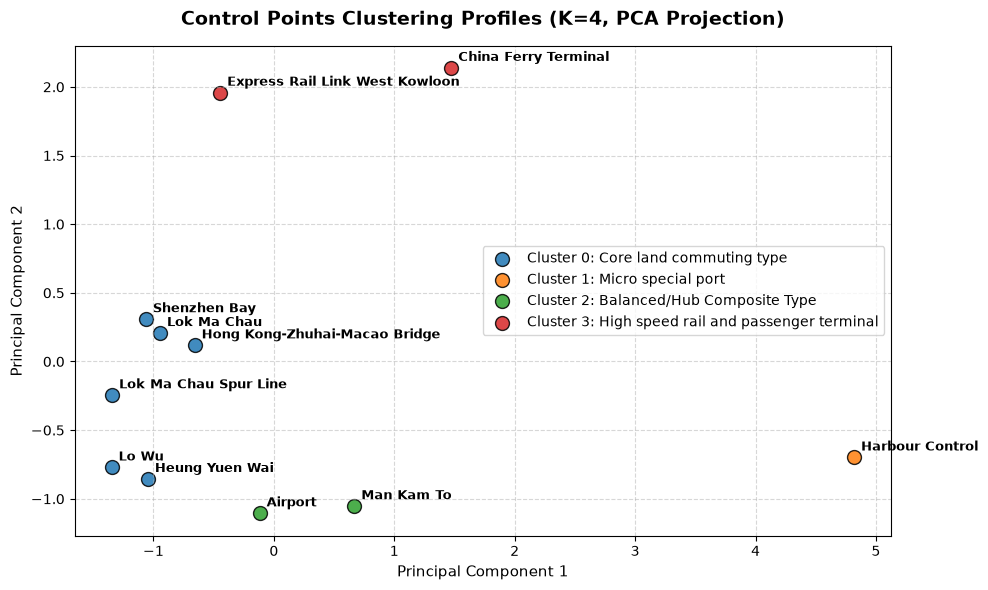

In [28]:
import matplotlib.pyplot as plt

# 2. 使用 PCA 将高维特征降维到二维平面用于可视化
from numpy.linalg import svd
# 手写简易 PCA (避免引入 sklearn 依赖)
X_centered = X_scaled - X_scaled.mean(axis=0)
U, S, Vt = svd(X_centered, full_matrices=False)
X_pca = X_centered @ Vt[:2].T  # 前两个主成分

df_feat['PCA1'] = X_pca[:, 0]
df_feat['PCA2'] = X_pca[:, 1]

# 3. 绘制可视化图表
fig, ax = plt.subplots(figsize=(10, 6))

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
cluster_names = {
    0: 'Cluster 0: Core land commuting type',
    1: 'Cluster 1: Micro special port',
    2: 'Cluster 2: Balanced/Hub Composite Type',
    3: 'Cluster 3: High speed rail and passenger terminal'
}

for cluster_id in range(k_target):
    subset = df_feat[df_feat['Cluster'] == cluster_id]
    ax.scatter(subset['PCA1'], subset['PCA2'], 
               c=colors[cluster_id], label=cluster_names[cluster_id], 
               s=100, alpha=0.85, edgecolors='k')
    
    # 在散点旁标注口岸名称
    for cp_name, row in subset.iterrows():
        ax.annotate(cp_name, (row['PCA1'], row['PCA2']), 
                    xytext=(5, 5), textcoords='offset points', fontsize=9, fontweight='bold')

ax.set_title('Control Points Clustering Profiles (K=4, PCA Projection)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Principal Component 1', fontsize=11)
ax.set_ylabel('Principal Component 2', fontsize=11)
ax.legend(loc='best', frameon=True)
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()